In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

y10 = pd.read_excel("DGS10 Monthly.xlsx")

In [11]:
y10.columns = ["date", "y10"]

In [12]:
y10.head()
y10.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    122 non-null    datetime64[ns]
 1   y10     122 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.0 KB


In [13]:
y10["date"] = pd.to_datetime(y10["date"])

# Move to end-of-month timestamp
y10["date"] = y10["date"] + pd.offsets.MonthEnd(0)

y10 = y10.sort_values("date")

In [14]:
y10.head()

,date,y10
0,2015-11-30,2.21
1,2015-12-31,2.27
2,2016-01-31,1.94
3,2016-02-29,1.74
4,2016-03-31,1.78


In [15]:
y10["dy10"] = y10["y10"] - y10["y10"].shift(1)

In [16]:
y10 = y10.dropna()

In [17]:
y10 = y10[y10["date"] >= "2015-12-31"]

In [18]:
y10.shape

(121, 3)

In [19]:
y10["dy10"].describe()

count    121.000000
mean       0.016281
std        0.242075
min       -0.520000
25%       -0.120000
50%        0.010000
75%        0.160000
max        0.680000
Name: dy10, dtype: float64

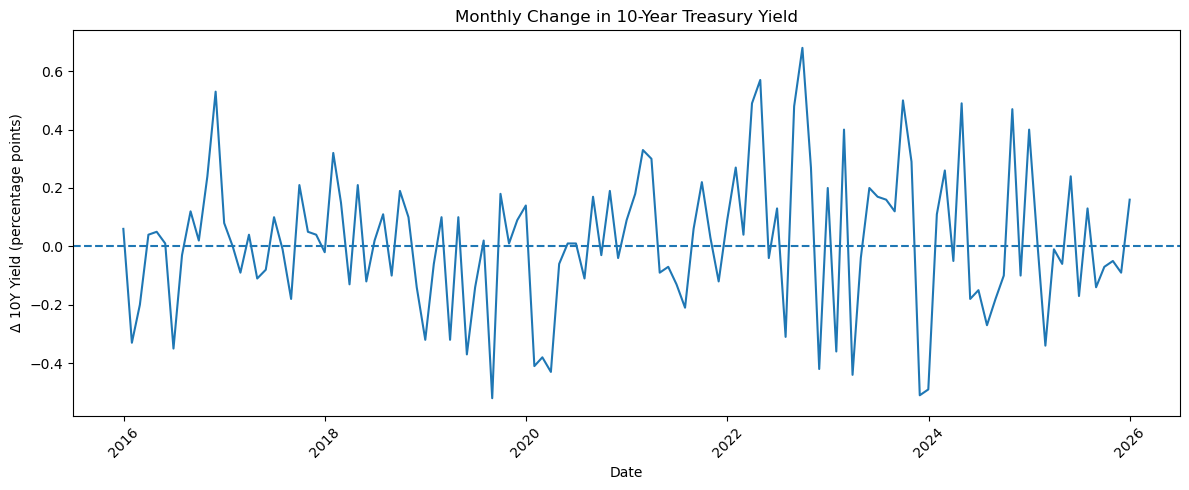

In [20]:
plt.figure(figsize=(12,5))

plt.plot(y10["date"], y10["dy10"])
plt.axhline(0, linestyle="--")

plt.title("Monthly Change in 10-Year Treasury Yield")
plt.xlabel("Date")
plt.ylabel("Δ 10Y Yield (percentage points)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
y10.head()

,date,y10,dy10
1,2015-12-31,2.27,0.06
2,2016-01-31,1.94,-0.33
3,2016-02-29,1.74,-0.20
4,2016-03-31,1.78,0.04
5,2016-04-30,1.83,0.05


In [22]:
y10_final = y10[["date", "dy10"]].copy()
y10_final = y10_final.sort_values("date")

y10_final.to_csv("dgs10_clean.csv", index=False)